In [77]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib
from sklearn.ensemble import IsolationForest

In [78]:
file_path = "../data/household_power_consumption.txt"

df = pd.read_csv(file_path,sep=";",low_memory=False)

In [3]:
df.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,17.0


In [4]:
df.shape

(2075259, 9)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   str    
 1   Time                   str    
 2   Global_active_power    str    
 3   Global_reactive_power  str    
 4   Voltage                str    
 5   Global_intensity       str    
 6   Sub_metering_1         str    
 7   Sub_metering_2         str    
 8   Sub_metering_3         float64
dtypes: float64(1), str(8)
memory usage: 239.1 MB


In [6]:
df.describe(include="all")

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
count,2075259,2075259,2075259,2075259,2075259,2075259,2075259,2075259,2.049280e+06
unique,1442,1440,4187,533,2838,222,89,82,NaN
top,17/12/2006,17:24:00,?,0.000,?,1.000,0.000,0.000,NaN
freq,1440,1442,25979,481561,25979,172785,1880175,1436830,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.458447e+00
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.437154e+00
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000e+00
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000e+00
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000e+00
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.700000e+01


In [7]:
df.columns.tolist()

['Date',
 'Time',
 'Global_active_power',
 'Global_reactive_power',
 'Voltage',
 'Global_intensity',
 'Sub_metering_1',
 'Sub_metering_2',
 'Sub_metering_3']

In [8]:
df.dtypes

Date                         str
Time                         str
Global_active_power          str
Global_reactive_power        str
Voltage                      str
Global_intensity             str
Sub_metering_1               str
Sub_metering_2               str
Sub_metering_3           float64
dtype: object

In [9]:
missing_values = df.isnull().sum()
missing_values

Date                         0
Time                         0
Global_active_power          0
Global_reactive_power        0
Voltage                      0
Global_intensity             0
Sub_metering_1               0
Sub_metering_2               0
Sub_metering_3           25979
dtype: int64

In [10]:
missing_percentage = (df.isnull().sum() / len(df)) * 100
missing_percentage.sort_values(ascending=False)

Sub_metering_3           1.251844
Date                     0.000000
Time                     0.000000
Global_reactive_power    0.000000
Global_active_power      0.000000
Voltage                  0.000000
Global_intensity         0.000000
Sub_metering_1           0.000000
Sub_metering_2           0.000000
dtype: float64

In [18]:
missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

missing_report.sort_values(
    by="Missing_Count",
    ascending=False
)

,Missing_Count,Missing_Percentage
Sub_metering_3,25979,1.25
Date,0,0.00
Time,0,0.00
Global_reactive_power,0,0.00
Global_active_power,0,0.00
Voltage,0,0.00
Global_intensity,0,0.00
Sub_metering_1,0,0.00
Sub_metering_2,0,0.00


In [22]:
df.replace("?", np.nan, inplace=True)

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,17.0
...,...,...,...,...,...,...,...,...,...
2075254,26/11/2010,20:58:00,0.946,0.000,240.430,4.000,0.000,0.000,0.0
2075255,26/11/2010,20:59:00,0.944,0.000,240.000,4.000,0.000,0.000,0.0
2075256,26/11/2010,21:00:00,0.938,0.000,239.820,3.800,0.000,0.000,0.0
2075257,26/11/2010,21:01:00,0.934,0.000,239.700,3.800,0.000,0.000,0.0


In [23]:
numeric_columns = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

In [24]:
for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [25]:
df[numeric_columns] = df[numeric_columns].interpolate(
    method="linear",
    limit_direction="both"
)

In [26]:
print(df[numeric_columns].isnull().sum())
print("Total Missing Values:", df.isnull().sum().sum())

Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64
Total Missing Values: 0


In [27]:
df.duplicated().sum()

np.int64(0)

In [28]:
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)

In [29]:
print("Dataset Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

Dataset Shape: (2075259, 9)
Missing Values: 0
Duplicate Rows: 0


In [30]:
df["Datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

In [31]:
df.drop(columns=["Date", "Time"], inplace=True)

In [32]:
df.sort_values("Datetime", inplace=True)
df.reset_index(drop=True, inplace=True)

In [33]:
df["Year"] = df["Datetime"].dt.year
df["Month"] = df["Datetime"].dt.month
df["Day"] = df["Datetime"].dt.day
df["Hour"] = df["Datetime"].dt.hour
df["DayOfWeek"] = df["Datetime"].dt.dayofweek
df["IsWeekend"] = (df["DayOfWeek"] >= 5).astype(int)

In [34]:
df.head()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Datetime,Year,Month,Day,Hour,DayOfWeek,IsWeekend
0,4.216,0.418,234.84,18.4,0.0,1.0,17.0,2006-12-16 17:24:00,2006,12,16,17,5,1
1,5.360,0.436,233.63,23.0,0.0,1.0,16.0,2006-12-16 17:25:00,2006,12,16,17,5,1
2,5.374,0.498,233.29,23.0,0.0,2.0,17.0,2006-12-16 17:26:00,2006,12,16,17,5,1
3,5.388,0.502,233.74,23.0,0.0,1.0,17.0,2006-12-16 17:27:00,2006,12,16,17,5,1
4,3.666,0.528,235.68,15.8,0.0,1.0,17.0,2006-12-16 17:28:00,2006,12,16,17,5,1


In [35]:
os.makedirs("../data", exist_ok=True)
df.to_csv("../data/cleaned_energy_data.csv",index=False)

In [37]:
image_path = "../images"
os.makedirs(image_path, exist_ok=True)

In [36]:
df["Global_active_power"].describe()

count    2.075259e+06
mean     1.090280e+00
std      1.052628e+00
min      7.600000e-02
25%      3.100000e-01
50%      6.140000e-01
75%      1.528000e+00
max      1.112200e+01
Name: Global_active_power, dtype: float64

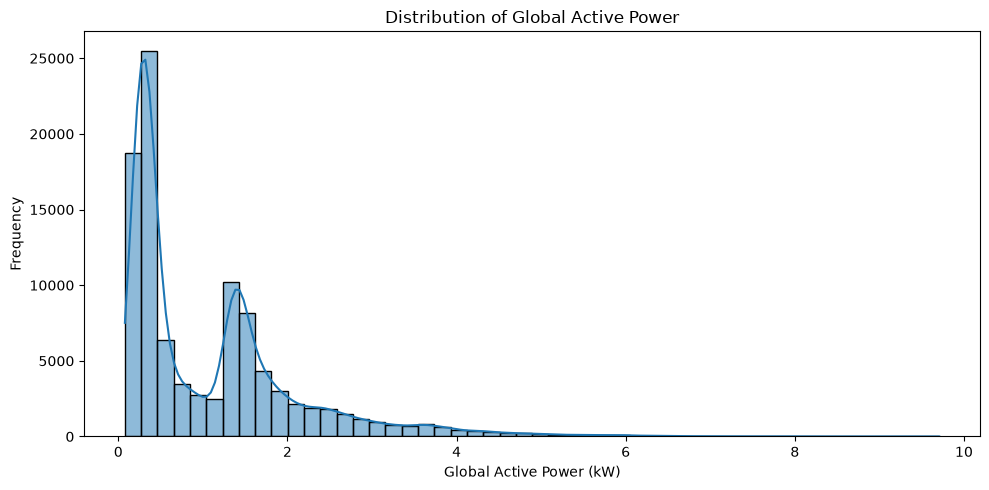

In [38]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["Global_active_power"].sample(
        n=min(100000, len(df)),
        random_state=42
    ),
    bins=50,
    kde=True
)

plt.title("Distribution of Global Active Power")
plt.xlabel("Global Active Power (kW)")
plt.ylabel("Frequency")
plt.tight_layout()

plt.savefig(
    os.path.join(image_path, "power_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

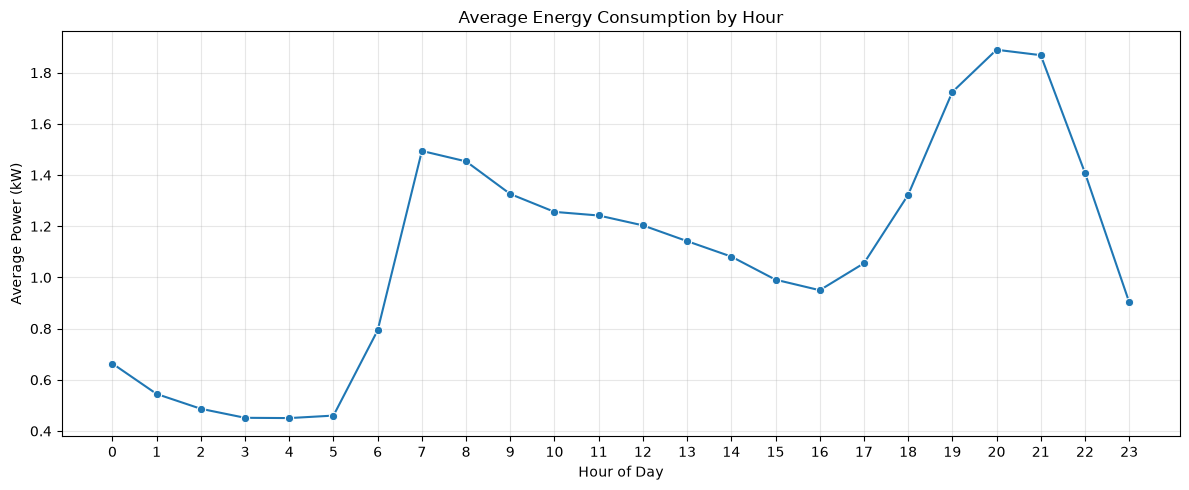

In [39]:
hourly_consumption = df.groupby("Hour")[
    "Global_active_power"
].mean()

plt.figure(figsize=(12, 5))

sns.lineplot(
    x=hourly_consumption.index,
    y=hourly_consumption.values,
    marker="o"
)

plt.title("Average Energy Consumption by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Power (kW)")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(image_path, "hourly_consumption.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

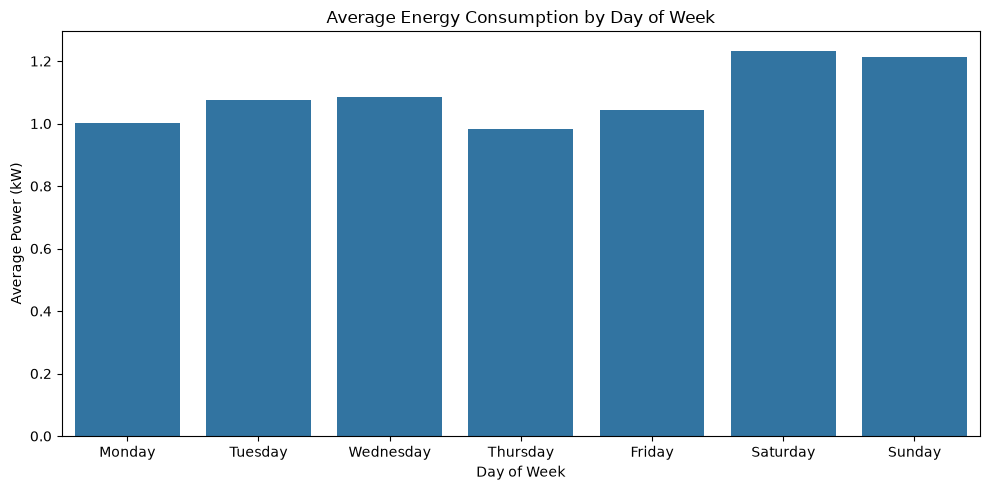

In [40]:
weekly_consumption = df.groupby("DayOfWeek")[
    "Global_active_power"
].mean()

plt.figure(figsize=(10, 5))

sns.barplot(
    x=weekly_consumption.index,
    y=weekly_consumption.values
)

plt.title("Average Energy Consumption by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Power (kW)")
plt.xticks(
    range(7),
    ["Monday", "Tuesday", "Wednesday", "Thursday",
     "Friday", "Saturday", "Sunday"]
)

plt.tight_layout()

plt.savefig(
    os.path.join(image_path, "weekly_consumption.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

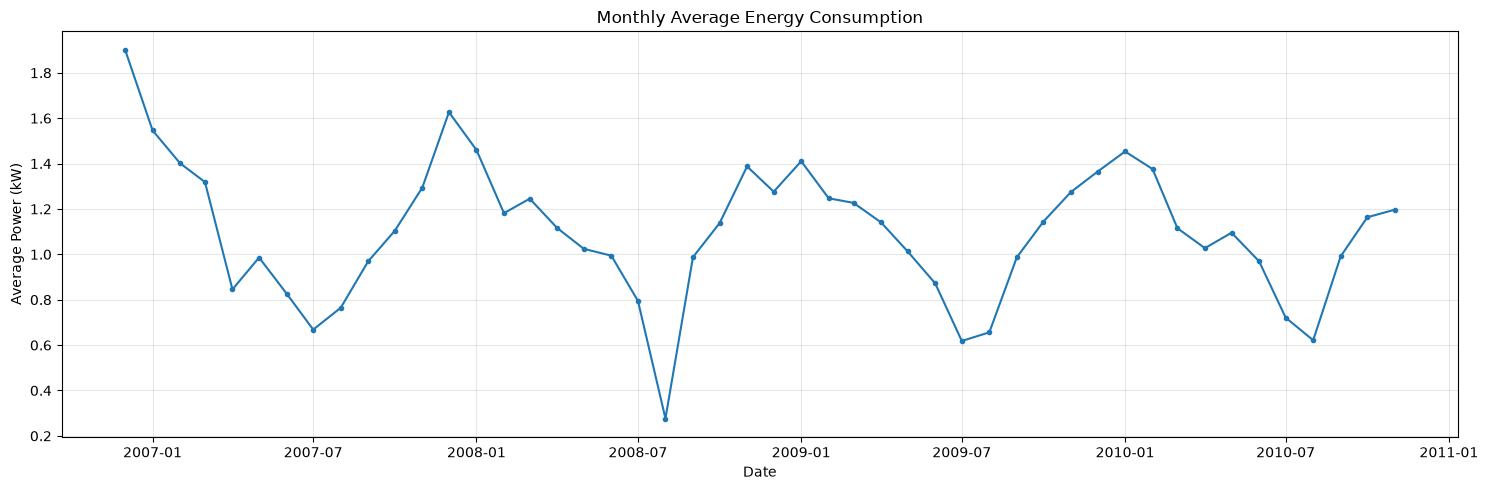

In [41]:
monthly_consumption = (
    df.set_index("Datetime")
    ["Global_active_power"]
    .resample("MS")
    .mean()
)

plt.figure(figsize=(15, 5))

plt.plot(
    monthly_consumption.index,
    monthly_consumption.values,
    marker="o",
    markersize=3
)

plt.title("Monthly Average Energy Consumption")
plt.xlabel("Date")
plt.ylabel("Average Power (kW)")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(image_path, "monthly_consumption.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [42]:
df_hourly = (
    df.set_index("Datetime")
    ["Global_active_power"]
    .resample("h")
    .mean()
    .reset_index()
)

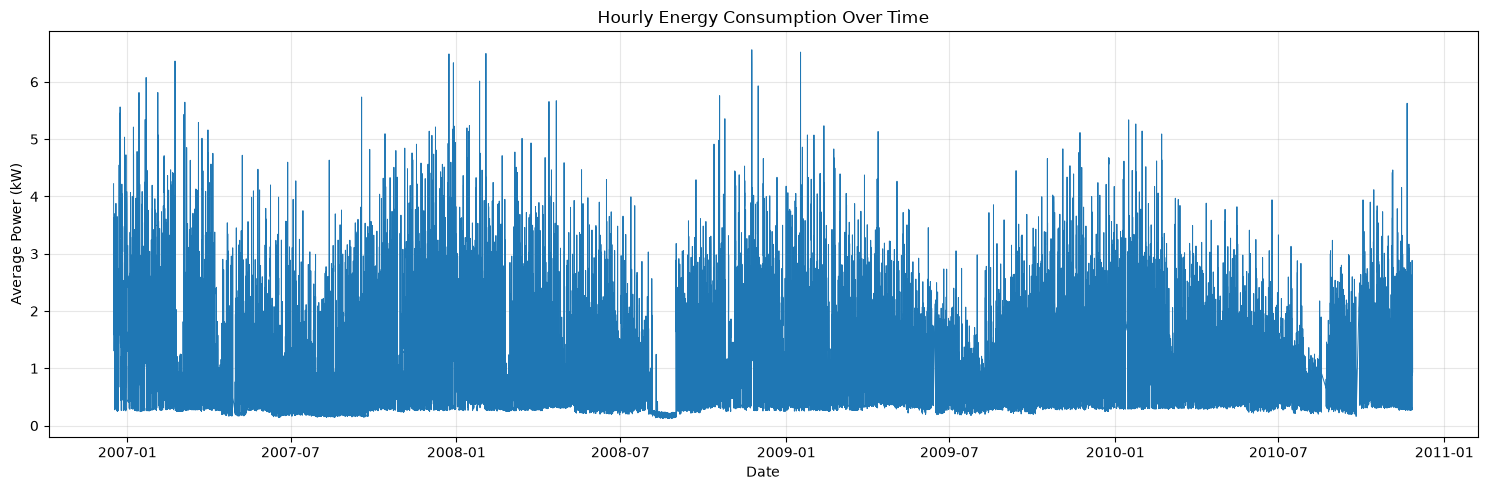

In [43]:
plt.figure(figsize=(15, 5))

plt.plot(
    df_hourly["Datetime"],
    df_hourly["Global_active_power"],
    linewidth=0.7
)

plt.title("Hourly Energy Consumption Over Time")
plt.xlabel("Date")
plt.ylabel("Average Power (kW)")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(image_path, "hourly_consumption_trend.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [44]:
df_hourly = df_hourly.sort_values("Datetime").reset_index(drop=True)

In [45]:
df_hourly["Hour"] = df_hourly["Datetime"].dt.hour
df_hourly["Day"] = df_hourly["Datetime"].dt.day
df_hourly["Month"] = df_hourly["Datetime"].dt.month
df_hourly["DayOfWeek"] = df_hourly["Datetime"].dt.dayofweek
df_hourly["IsWeekend"] = (df_hourly["DayOfWeek"] >= 5).astype(int)

In [46]:
df_hourly["Lag_1"] = df_hourly["Global_active_power"].shift(1)
df_hourly["Lag_24"] = df_hourly["Global_active_power"].shift(24)
df_hourly["Lag_168"] = df_hourly["Global_active_power"].shift(168)

In [47]:
df_hourly["Rolling_Mean_24"] = (
    df_hourly["Global_active_power"]
    .shift(1)
    .rolling(window=24)
    .mean()
)

df_hourly["Rolling_Mean_168"] = (
    df_hourly["Global_active_power"]
    .shift(1)
    .rolling(window=168)
    .mean()
)

In [48]:
df_hourly.dropna(inplace=True)
df_hourly.reset_index(drop=True, inplace=True)

In [49]:
df_hourly.head()

,Datetime,Global_active_power,Hour,Day,Month,DayOfWeek,IsWeekend,Lag_1,Lag_24,Lag_168,Rolling_Mean_24,Rolling_Mean_168
0,2006-12-23 17:00:00,5.452533,17,23,12,5,1,4.349100,1.496800,4.222889,2.934890,1.763888
1,2006-12-23 18:00:00,3.879400,18,23,12,5,1,5.452533,2.686967,3.632200,3.099713,1.771207
2,2006-12-23 19:00:00,4.117833,19,23,12,5,1,3.879400,3.938167,3.400233,3.149397,1.772679
3,2006-12-23 20:00:00,4.181400,20,23,12,5,1,4.117833,3.536067,3.268567,3.156883,1.776950
4,2006-12-23 21:00:00,3.288433,21,23,12,5,1,4.181400,4.548667,3.056467,3.183772,1.782384


In [50]:
df_hourly.to_csv( "../data/energy_features.csv", index=False)

In [51]:
print("Dataset Shape:", df_hourly.shape)
print("\nMissing Values:", df_hourly.isnull().sum().sum())
print("\nColumns:", df_hourly.columns.tolist())

Dataset Shape: (34421, 12)

Missing Values: 0

Columns: ['Datetime', 'Global_active_power', 'Hour', 'Day', 'Month', 'DayOfWeek', 'IsWeekend', 'Lag_1', 'Lag_24', 'Lag_168', 'Rolling_Mean_24', 'Rolling_Mean_168']


In [52]:
features = ["Hour", "Day", "Month", "DayOfWeek", "IsWeekend", "Lag_1", "Lag_24", "Lag_168", "Rolling_Mean_24", "Rolling_Mean_168"]
target = "Global_active_power"

X = df_hourly[features]
y = df_hourly[target]

In [53]:
n = len(df_hourly)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train, y_train = X.iloc[:train_end], y.iloc[:train_end]
X_val, y_val = X.iloc[train_end:val_end], y.iloc[train_end:val_end]
X_test, y_test = X.iloc[val_end:], y.iloc[val_end:]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (24094, 10)
Validation: (5163, 10)
Testing: (5164, 10)


In [55]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=15, min_samples_leaf=2, random_state=42, n_jobs=-1),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, max_leaf_nodes=31, random_state=42)
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained successfully.")

Linear Regression trained successfully.
Random Forest trained successfully.
Hist Gradient Boosting trained successfully.


In [57]:
results = []
for name, model in models.items():
    predictions = model.predict(X_val)
    mae = mean_absolute_error(y_val, predictions)
    rmse = np.sqrt(mean_squared_error(y_val, predictions))
    r2 = r2_score(y_val, predictions)
    results.append({"Model": name, "MAE": mae, "RMSE": rmse, "R2": r2})

validation_results = pd.DataFrame(results).sort_values("RMSE")
validation_results

,Model,MAE,RMSE,R2
2,Hist Gradient Boosting,0.368650,0.532723,0.636107
1,Random Forest,0.378389,0.548143,0.614735
0,Linear Regression,0.422062,0.591518,0.551351


In [58]:
best_model_name = validation_results.iloc[0]["Model"]
best_model = models[best_model_name]

test_predictions = best_model.predict(X_test)

print("Best Model:", best_model_name)
print("Test MAE:", mean_absolute_error(y_test, test_predictions))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, test_predictions)))
print("Test R2:", r2_score(y_test, test_predictions))

Best Model: Hist Gradient Boosting
Test MAE: 0.32427783256264964
Test RMSE: 0.46487721548331956
Test R2: 0.5613384336688634


In [61]:
os.makedirs("../models", exist_ok=True)
joblib.dump(best_model, "../models/best_energy_model.pkl")
validation_results.to_csv("../data/model_comparison.csv", index=False)

print("Model and evaluation results saved successfully.")

Model and evaluation results saved successfully.


In [62]:
comparison_df = pd.DataFrame({"Datetime": df_hourly["Datetime"].iloc[val_end:].values, "Actual": y_test.values, "Predicted": test_predictions})
comparison_df.head()

,Datetime,Actual,Predicted
0,2010-04-25 18:00:00,0.382767,0.784887
1,2010-04-25 19:00:00,0.435367,1.012002
2,2010-04-25 20:00:00,0.368333,1.098812
3,2010-04-25 21:00:00,0.367833,0.886160
4,2010-04-25 22:00:00,0.921433,0.587357


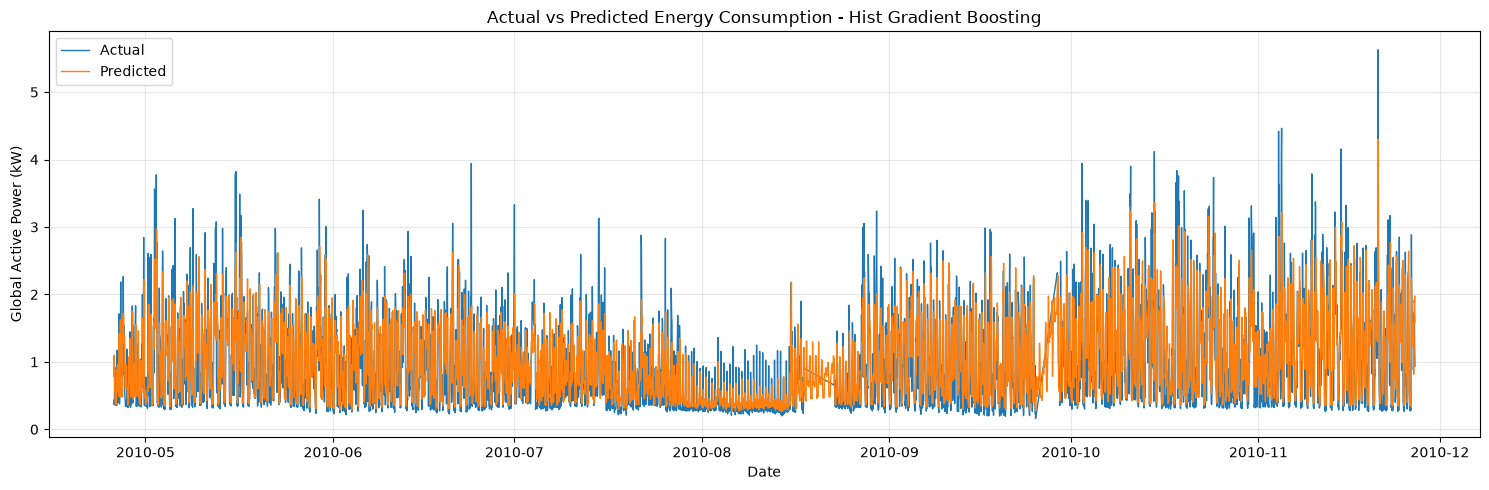

In [63]:
plt.figure(figsize=(15, 5))
plt.plot(comparison_df["Datetime"], comparison_df["Actual"], label="Actual", linewidth=1)
plt.plot(comparison_df["Datetime"], comparison_df["Predicted"], label="Predicted", linewidth=1)
plt.title(f"Actual vs Predicted Energy Consumption - {best_model_name}")
plt.xlabel("Date")
plt.ylabel("Global Active Power (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(image_path, "actual_vs_predicted.png"), dpi=300, bbox_inches="tight")
plt.show()

In [64]:
comparison_df["Error"] = comparison_df["Actual"] - comparison_df["Predicted"]
comparison_df["Absolute_Error"] = comparison_df["Error"].abs()
print("Mean Absolute Error:", comparison_df["Absolute_Error"].mean())
print("Maximum Absolute Error:", comparison_df["Absolute_Error"].max())

Mean Absolute Error: 0.32427783256264964
Maximum Absolute Error: 3.482192696571477


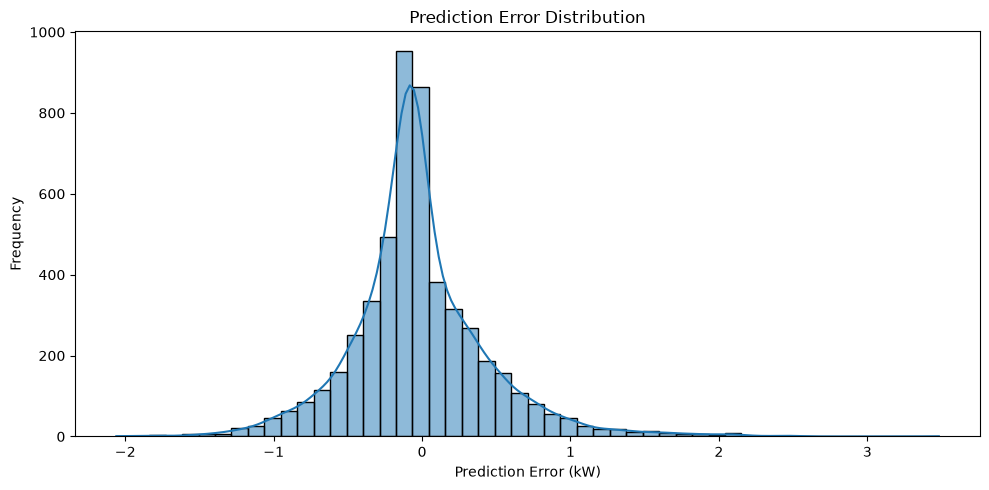

In [65]:
plt.figure(figsize=(10, 5))
sns.histplot(comparison_df["Error"], bins=50, kde=True)
plt.title("Prediction Error Distribution")
plt.xlabel("Prediction Error (kW)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig(os.path.join(image_path, "prediction_error_distribution.png"), dpi=300, bbox_inches="tight")
plt.show()

In [66]:
comparison_df.to_csv("../data/test_predictions.csv", index=False)

In [67]:
anomaly_data = df_hourly[["Datetime", "Global_active_power"]].copy()

In [69]:
iso_forest = IsolationForest(n_estimators=100, contamination=0.02, random_state=42)
anomaly_data["Anomaly"] = iso_forest.fit_predict(anomaly_data[["Global_active_power"]])
anomaly_data["Anomaly"] = anomaly_data["Anomaly"].map({1: "Normal", -1: "Anomaly"})

In [70]:
anomaly_data["Anomaly"].value_counts()

Anomaly
Normal     33739
Anomaly      682
Name: count, dtype: int64

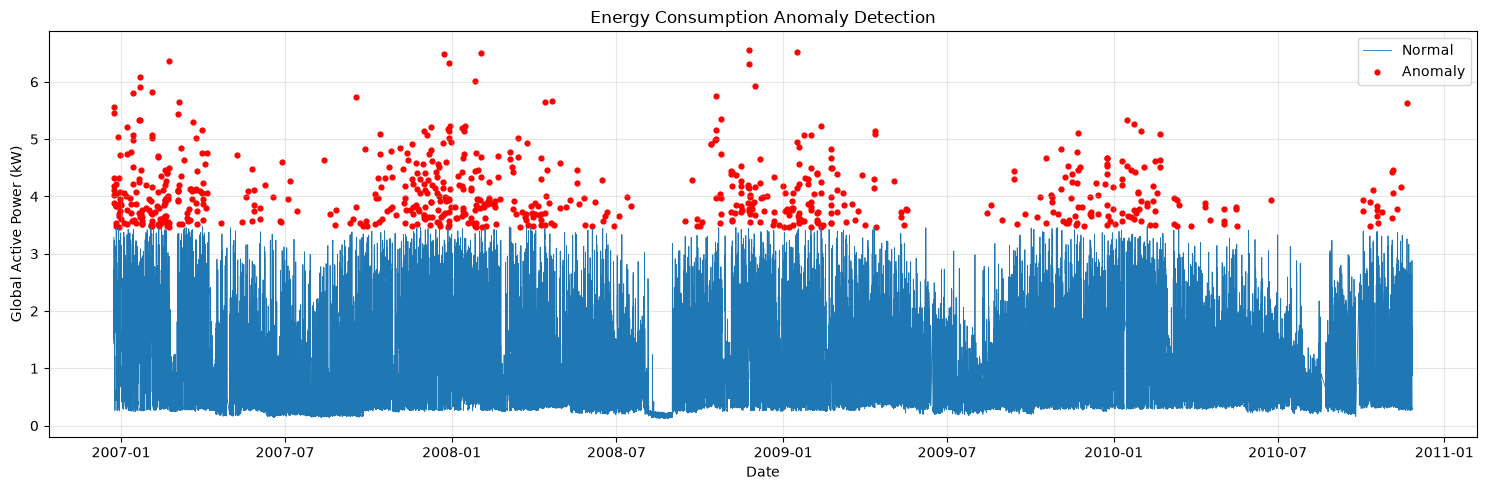

In [71]:
plt.figure(figsize=(15, 5))
normal = anomaly_data[anomaly_data["Anomaly"] == "Normal"]
anomalies = anomaly_data[anomaly_data["Anomaly"] == "Anomaly"]
plt.plot(normal["Datetime"], normal["Global_active_power"], linewidth=0.6, label="Normal")
plt.scatter(anomalies["Datetime"], anomalies["Global_active_power"], color="red", s=12, label="Anomaly")
plt.title("Energy Consumption Anomaly Detection")
plt.xlabel("Date")
plt.ylabel("Global Active Power (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(image_path, "anomaly_detection.png"), dpi=300, bbox_inches="tight")
plt.show()

In [72]:
anomaly_data.to_csv("../data/anomaly_results.csv", index=False)